In [1]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
#Abro el archivo y lo leo, indicando la ruta donde se encuentra guardado.
#Tipo de dato incorrecto. Si una columna numérica figura como object, probablemente tiene texto mezclado
df = pd.read_csv('base_datos_restaurantes_USA_v2.csv', encoding='utf-8')
df.info()
df

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_persona                 30000 non-null  int64  
 1   nombre                     30000 non-null  str    
 2   apellido                   30000 non-null  str    
 3   edad                       29899 non-null  float64
 4   genero                     30000 non-null  str    
 5   ciudad_residencia          30000 non-null  str    
 6   estrato_socioeconomico     30000 non-null  str    
 7   frecuencia_visita          30000 non-null  int64  
 8   promedio_gasto_comida      29855 non-null  float64
 9   ocio                       30000 non-null  str    
 10  consume_licor              30000 non-null  str    
 11  preferencias_alimenticias  28597 non-null  str    
 12  membresia_premium          30000 non-null  str    
 13  telefono_contacto          14834 non-null  str    
 14  c

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,(830)220-1926,NaN,Efectivo,6425
1,9446112038,Samantha,Soto,40.0,Femenino,Denver,Medio,2,44.92,Sí,Sí,Mariscos,No,881-476-1426,NaN,Efectivo,2374
2,3098363243,Terry,Adams,62.0,Femenino,Denver,Bajo,2,9.24,Sí,Sí,Vegetariano,No,NaN,diana74@example.net,Efectivo,1110
3,4013002847,James,Shannon,41.0,Masculino,Boston,Alto,5,30.74,Sí,Sí,Carnes,Sí,NaN,scottfrey@example.com,Tarjeta,6931
4,7372911048,Susan,Jones,49.0,Femenino,San Diego,Bajo,0,0.00,No,No,Carnes,No,243.248.8919,glassgary@example.org,Tarjeta,1350
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,4862097674,Robert,Cortez,20.0,Masculino,Houston,Alto,-3,30.82,Sí,Sí,Vegano,Sí,NaN,garciagregory@example.net,Tarjeta,5781
29996,9458262482,Michael,Holt,78.0,Masculino,Denver,Alto,5,45.04,No,No,Mariscos,No,NaN,jimmy77@example.org,Efectivo,7652
29997,3412365931,Rebecca,Henry,77.0,Femenino,San Diego,Muy Alto,7,93.55,No,Sí,Mariscos,Sí,NaN,NaN,Efectivo,12639
29998,8853079811,Tamara,Griffin,77.0,Femenino,Chicago,Bajo,1,6.18,Sí,No,Otro,No,(243)658-6543x11668,NaN,Tarjeta,1057


In [3]:
 #Veo si hay filas completas duplicadas
df[df.duplicated()]

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales


In [4]:
#Veo si id_persona esta duplicado
df['id_persona'].duplicated().sum()


np.int64(0)

In [5]:
#veo si telefono_contacto esta duplicado. Decido no hacer nada con los duplicados, dado que no se a la persona correcta a la cual pertenece
df['telefono_contacto'].duplicated().sum()

np.int64(15165)

In [6]:
#veo si correo_electronico esta duplicado. Decido no hacer nada con los duplicados, dado que no se a la persona correcta a la cual pertenece
df['correo_electronico'].duplicated().sum()

np.int64(15525)

In [7]:
#Analizando el Data Wrangler veo que hay edades menores a cero y mayores a 110; por lo tanto, calculo el promedio de edad dentro del margen certero y luego completo los datos nulos y datos erroneos con dicho promedio
promedio = df.loc[(df['edad'] >= 0) & (df['edad'] <= 110), 'edad'].mean()
df.loc[df['edad'].isnull() | (df['edad'] < 0) | (df['edad'] > 110), 'edad'] = promedio

In [8]:
# 1. Promedio de gasto, sin ceros (los nulos los ignora mean())
promedio_gasto = df.loc[df['promedio_gasto_comida'] != 0, 'promedio_gasto_comida'].mean()

# 2. Rellenar nulos solo donde frecuencia_visita != 0
mask = df['promedio_gasto_comida'].isnull() & (df['frecuencia_visita'] != 0)
df.loc[mask, 'promedio_gasto_comida'] = promedio_gasto

In [9]:
# Caso 1: frecuencia negativa y gasto > 0 -> pasar a positivo
mask_positivo = (df['frecuencia_visita'] < 0) & (df['promedio_gasto_comida'] > 0)
df.loc[mask_positivo, 'frecuencia_visita'] = df.loc[mask_positivo, 'frecuencia_visita'].abs()

In [10]:
#Veo categorias de preferencias_alimenticias y las cantidades
df['preferencias_alimenticias'].value_counts()

preferencias_alimenticias
Carnes         7916
Vegetariano    6580
Mariscos       5212
Vegano         3267
Pescado        2983
Otro           2639
Name: count, dtype: int64

In [11]:
#En preferencias_alimenticias hay 1403 datos faltantes; decido completar repartiendo en partes iguales de cada una de las 6 categorias para no afectar el promedio.
categorias = ['Carnes', 'Vegetariano', 'Mariscos', 'Vegano', 'Pescado', 'Otro']

mask = df['preferencias_alimenticias'].isnull()
n = mask.sum()

# Lista con las categorías repetidas en partes iguales (el resto se reparte de a una)
valores = np.resize(categorias, n)

# Mezclar para que no queden agrupadas en bloques
rng = np.random.default_rng(42)
rng.shuffle(valores)

df.loc[mask, 'preferencias_alimenticias'] = valores

In [12]:
#Nulos - Cantidad
df.isnull().sum()


id_persona                       0
nombre                           0
apellido                         0
edad                             0
genero                           0
ciudad_residencia                0
estrato_socioeconomico           0
frecuencia_visita                0
promedio_gasto_comida            0
ocio                             0
consume_licor                    0
preferencias_alimenticias        0
membresia_premium                0
telefono_contacto            15166
correo_electronico           15072
tipo_de_pago_mas_usado           0
ingresos_mensuales               0
dtype: int64

In [13]:
#Nulos - Porcentaje
df.isnull().sum() / len(df) * 100

id_persona                    0.000000
nombre                        0.000000
apellido                      0.000000
edad                          0.000000
genero                        0.000000
ciudad_residencia             0.000000
estrato_socioeconomico        0.000000
frecuencia_visita             0.000000
promedio_gasto_comida         0.000000
ocio                          0.000000
consume_licor                 0.000000
preferencias_alimenticias     0.000000
membresia_premium             0.000000
telefono_contacto            50.553333
correo_electronico           50.240000
tipo_de_pago_mas_usado        0.000000
ingresos_mensuales            0.000000
dtype: float64

In [14]:
#Imputacion de nulos: donde hay nulos completo con: "S/D" (Sin Dato)
df['correo_electronico'] = df['correo_electronico'].fillna('S/D')

In [15]:
#Imputacion de nulos: donde hay nulos completo con: "S/D" (Sin Dato)
df['telefono_contacto'] = df['telefono_contacto'].fillna('S/D')

In [16]:
#Realizo una funcion de formateo para los numeros telefonicos. Estan escritos de diferente manera y con esta funcion los ordeno con la misma nomenclatura
def formatear_telefono(t):
    if pd.isnull(t) or t == 'S/D':
        return t

    t = str(t).strip()

    # 1. Separar la extensión (lo que viene después de la "x")
    partes = re.split(r'x', t, maxsplit=1, flags=re.IGNORECASE)
    base = partes[0]
    ext = re.sub(r'\D', '', partes[1]) if len(partes) > 1 else ''

    # 2. Dejar solo los dígitos del número principal
    digitos = re.sub(r'\D', '', base)

    # 3. Quitar el prefijo de país si viene como 001, +1 o 1
    if len(digitos) == 13 and digitos.startswith('001'):
        digitos = digitos[3:]
    elif len(digitos) == 11 and digitos.startswith('1'):
        digitos = digitos[1:]

    # 4. Si no quedan 10 dígitos, se deja el original sin tocar (para revisarlo)
    if len(digitos) != 10:
        return t

    # 5. Formato final: todos con +1, paréntesis y extensión
    resultado = f'+1 ({digitos[:3]}) {digitos[3:6]}-{digitos[6:]}'
    if ext:
        resultado += f' x{ext}'
    return resultado

df['telefono_contacto'] = df['telefono_contacto'].apply(formatear_telefono)

In [17]:
#Filtro la base de datos para una ciudad especifica
df_ciudad = df[df['ciudad_residencia'] == 'Miami']
df_ciudad

,id_persona,nombre,apellido,edad,genero,ciudad_residencia,estrato_socioeconomico,frecuencia_visita,promedio_gasto_comida,ocio,consume_licor,preferencias_alimenticias,membresia_premium,telefono_contacto,correo_electronico,tipo_de_pago_mas_usado,ingresos_mensuales
0,2550327378,Jackson,Gomez,31.0,Masculino,Miami,Alto,6,67.51,Sí,No,Vegetariano,Sí,+1 (830) 220-1926,S/D,Efectivo,6425
16,6139475525,Andrew,Soto,18.0,Masculino,Miami,Muy Alto,9,26.60,Sí,Sí,Vegetariano,Sí,+1 (285) 938-0942,ssteele@example.net,App,13452
37,5358661821,Elizabeth,Brown,79.0,Femenino,Miami,Muy Alto,6,28.43,No,No,Mariscos,Sí,+1 (464) 992-9070 x38394,S/D,Efectivo,14072
45,8593345998,Robert,Wilson,76.0,Masculino,Miami,Alto,5,43.00,Sí,No,Mariscos,Sí,S/D,S/D,App,6528
47,6170452916,Bruce,Young,55.0,Masculino,Miami,Muy Alto,5,119.85,Sí,No,Carnes,Sí,S/D,ltran@example.com,Efectivo,15844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29953,2238067088,Kevin,Taylor,45.0,Masculino,Miami,Medio,5,35.35,Sí,No,Vegetariano,Sí,+1 (748) 240-5443,jerrychavez@example.com,Efectivo,3174
29957,1161504159,Rachael,Martinez,58.0,Femenino,Miami,Medio,5,19.10,No,Sí,Pescado,No,+1 (775) 640-4909,wmalone@example.net,Efectivo,2157
29958,9452988778,William,Peters,50.0,Masculino,Miami,Bajo,2,14.65,Sí,Sí,Mariscos,No,S/D,S/D,Tarjeta,829
29985,8301681475,Gloria,Evans,38.0,Femenino,Miami,Alto,5,16.84,Sí,No,Carnes,Sí,+1 (950) 647-8528 x2958,marywilliams@example.net,Tarjeta,4853


In [18]:
#Tabla de preferencias alimenticias segun genero
porc = (pd.crosstab(df_ciudad['preferencias_alimenticias'], df_ciudad['genero'], normalize='index') * 100).round(2)
porc['Total personas'] = df_ciudad['preferencias_alimenticias'].value_counts()
porc


genero,Femenino,Masculino,Total personas
preferencias_alimenticias,,,
Carnes,52.26,47.74,530
Mariscos,47.60,52.40,834
Otro,47.17,52.83,318
Pescado,50.75,49.25,333
Vegano,45.43,54.57,416
Vegetariano,51.52,48.48,755


In [19]:
#Quiero ver cantidad de personas segun rango de edad, cantidad de visitas segun edad y tambien cuanto gastan segun la edad
d = df_ciudad.copy()

d['rango_edad'] = pd.cut(d['edad'],
                         bins=[0, 17, 25, 35, 45, 55, 65, 110],
                         labels=['0-17', '18-25', '26-35', '36-45', '46-55', '56-65', '66+'],
                         include_lowest=True)

tabla = (d.groupby('rango_edad', observed=True)
          .agg(personas=('edad', 'count'),
               visitas_totales=('frecuencia_visita', 'sum'),
               gasto_total=('promedio_gasto_comida', 'sum'),)
               
          .round(2))



tabla

,personas,visitas_totales,gasto_total
rango_edad,,,
18-25,342,1614,14358.91
26-35,528,2482,20709.03
36-45,545,2586,20876.60
46-55,568,2607,22397.54
56-65,452,2142,18401.44
66+,751,3494,30039.32


In [20]:
#Quiero ver la frecuencia de visita segun el lugar de residencia
visitas_por_ciudad = df.groupby('ciudad_residencia')['frecuencia_visita'].sum().sort_values(ascending=False)
visitas_por_ciudad

ciudad_residencia
Chicago      22304
NYC          18767
Miami        14925
San Diego    14096
Boston       10877
Denver       10521
Dallas       10295
Seattle       9517
Houston       8637
Phoenix       6227
Name: frecuencia_visita, dtype: int64

In [21]:
#Quiero ver las mil personas de mayor ingreso como abonan, la forma de pago.
top1000 = df.nlargest(1000, 'ingresos_mensuales')
top1000['tipo_de_pago_mas_usado'].value_counts()
pd.DataFrame({
    'cantidad': top1000['tipo_de_pago_mas_usado'].value_counts(dropna=False)
})

,cantidad
tipo_de_pago_mas_usado,
Efectivo,410
Tarjeta,347
App,229
Criptomoneda,14


In [22]:
#quiero ver segun el estrato_socioeconomico, la suma de promedio_gasto_comida y las visitas totales
orden = ['Bajo', 'Medio', 'Alto', 'Muy Alto']

tabla = (df_ciudad.groupby('estrato_socioeconomico')
                  .agg(personas=('estrato_socioeconomico', 'count'),
                       gasto_total=('promedio_gasto_comida', 'sum'),
                       gasto_promedio=('promedio_gasto_comida', 'mean'),
                       visitas_totales=('frecuencia_visita', 'sum'),)
                
                  .round(2)
                  .reindex(orden))
tabla

,personas,gasto_total,gasto_promedio,visitas_totales
estrato_socioeconomico,,,,
Bajo,445,5936.37,13.34,722
Medio,783,19556.92,24.98,2725
Alto,1159,46445.11,40.07,5678
Muy Alto,799,54844.42,68.64,5800


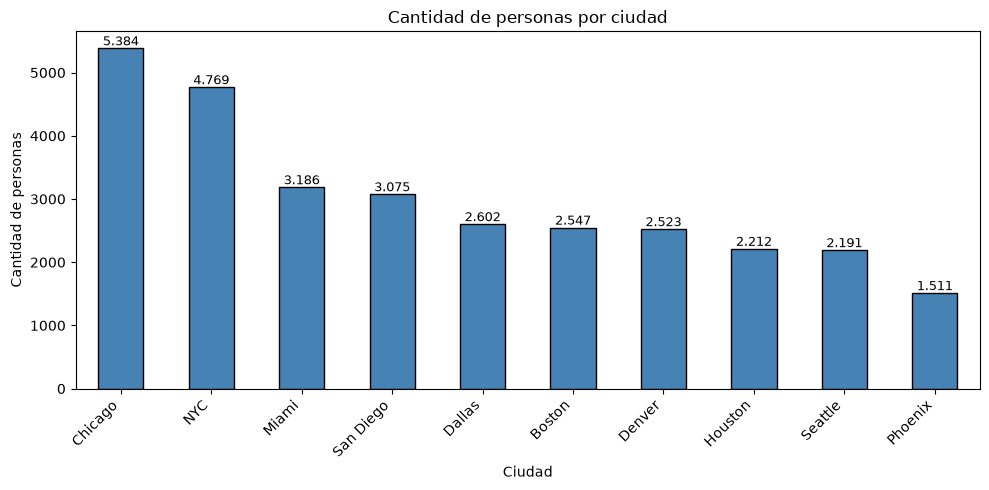

In [23]:
#                         **************************************         AVANCE 3        ****************************************

#Avance 3 - Grafico de cantidd de personas por ciudad
conteo = df['ciudad_residencia'].value_counts()

plt.figure(figsize=(10, 5))
ax = conteo.plot(kind='bar', color='steelblue', edgecolor='black')

plt.title('Cantidad de personas por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Cantidad de personas')
plt.xticks(rotation=45, ha='right')

# Mostrar el número encima de cada barra
for barra in ax.patches:
    ax.annotate(f'{int(barra.get_height()):,}'.replace(',', '.'),
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [24]:
#Avance 3 - Generar un listado que muestre cómo se distribuyen las personas en los diferentes estratos socioeconómicos

orden = ['Bajo', 'Medio', 'Alto', 'Muy Alto']

listado = pd.DataFrame({
    'cantidad': df['estrato_socioeconomico'].value_counts(),
    'porcentaje': (df['estrato_socioeconomico'].value_counts(normalize=True) * 100).round(2)
}).reindex(orden)

listado

,cantidad,porcentaje
estrato_socioeconomico,,
Bajo,6161,20.54
Medio,9325,31.08
Alto,9038,30.13
Muy Alto,5476,18.25


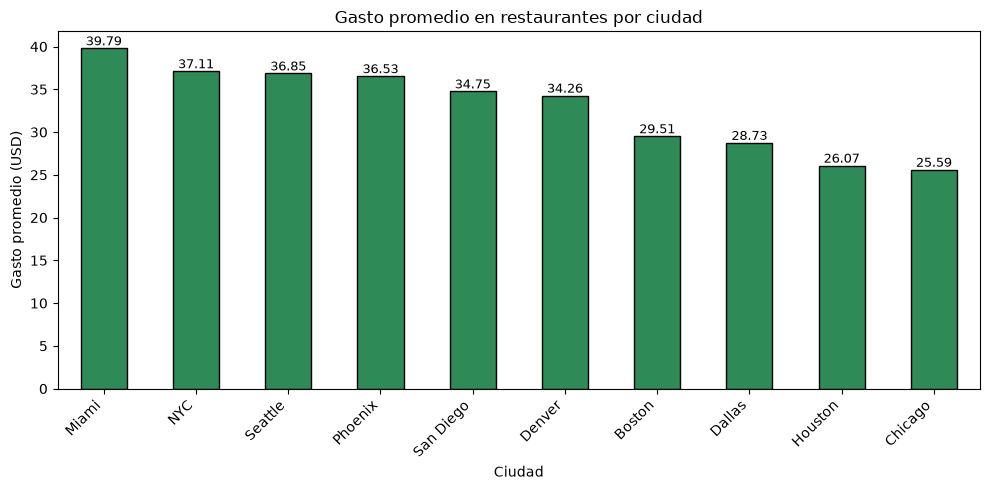

In [25]:
#Avance 3 - Hacer un gráfico que muestre cuáles son las ciudades en las que más dinero se gasta en promedio en restaurantes al mes.
gasto_ciudad = (df.groupby('ciudad_residencia')['promedio_gasto_comida']
                  .mean()
                  .sort_values(ascending=False)
                  .round(2))

plt.figure(figsize=(10, 5))
ax = gasto_ciudad.plot(kind='bar', color='seagreen', edgecolor='black')

plt.title('Gasto promedio en restaurantes por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Gasto promedio (USD)')
plt.xticks(rotation=45, ha='right')

for barra in ax.patches:
    ax.annotate(f'{barra.get_height():.2f}',
                (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

In [26]:
#Avance 3 - Generar un gráfico donde se evidencie cómo es la relación entre la frecuencia de visita a los restaurantes y el gasto promedio por comida según el estrato socioeconómico (lo hacemos en varias celdas:)
# 1 - Preparar los datos
orden = ['Bajo', 'Medio', 'Alto', 'Muy Alto']

d = df[(df['frecuencia_visita'] > 0) & (df['promedio_gasto_comida'] > 0)].copy()

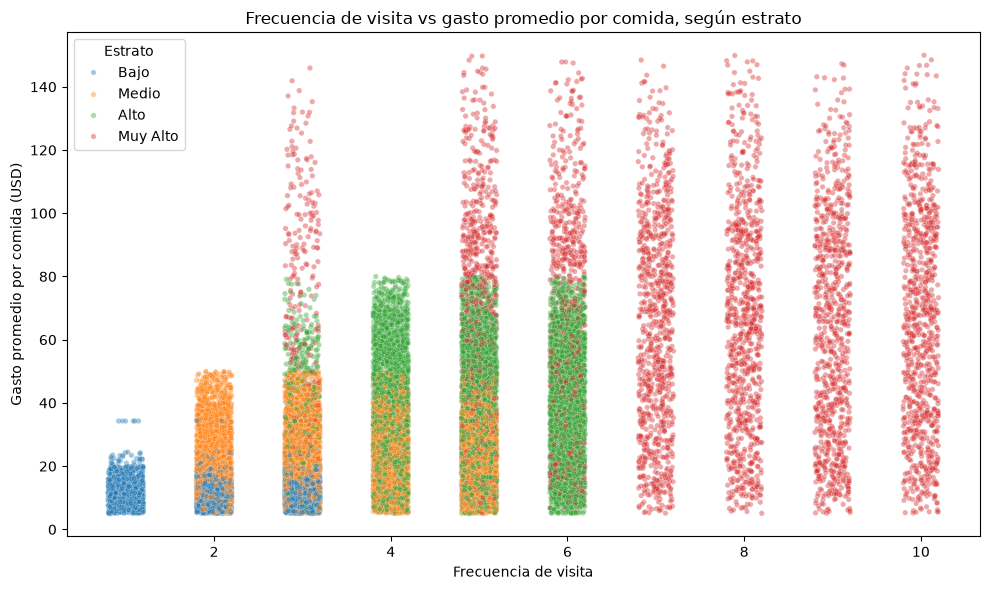

In [27]:
# 2 - Dispersión coloreada por estrato: (El jitter desplaza apenas cada punto en horizontal para que no se superpongan; no cambia los datos.)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=d.assign(frec_jitter=d['frecuencia_visita'] + np.random.uniform(-0.2, 0.2, len(d))),
                x='frec_jitter', y='promedio_gasto_comida',
                hue='estrato_socioeconomico', hue_order=orden,
                alpha=0.4, s=15)

plt.title('Frecuencia de visita vs gasto promedio por comida, según estrato')
plt.xlabel('Frecuencia de visita')
plt.ylabel('Gasto promedio por comida (USD)')
plt.legend(title='Estrato')
plt.tight_layout()
plt.show()

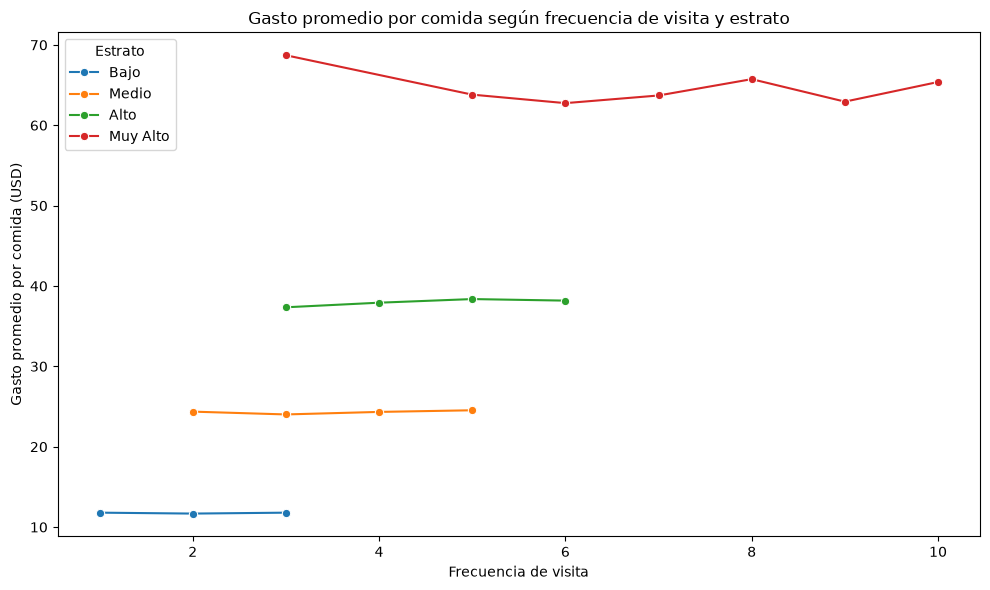

In [28]:
# 3 - Líneas con el gasto promedio por frecuencia (más fácil de leer):
plt.figure(figsize=(10, 6))
sns.lineplot(data=d, x='frecuencia_visita', y='promedio_gasto_comida',
             hue='estrato_socioeconomico', hue_order=orden,
             estimator='mean', errorbar=None, marker='o')

plt.title('Gasto promedio por comida según frecuencia de visita y estrato')
plt.xlabel('Frecuencia de visita')
plt.ylabel('Gasto promedio por comida (USD)')
plt.legend(title='Estrato')
plt.tight_layout()
plt.show()

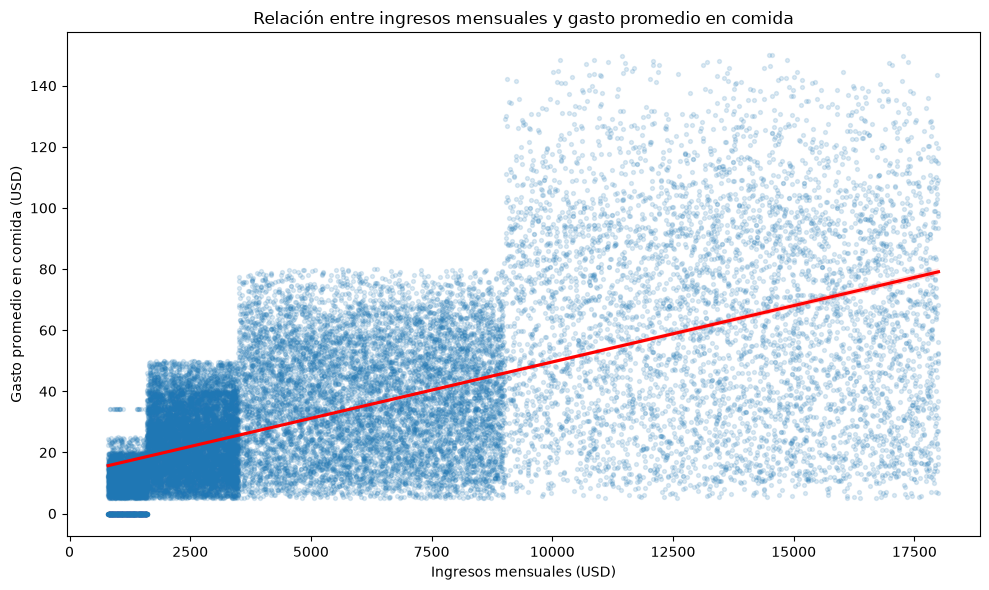

In [29]:
# Avance 3 - Crear un gráfico de dispersión que evidencie cómo es la relación entre el gasto promedio mensual de todas las personas y sus ingresos mensuales.
# (Un scatter entre ingresos_mensuales (eje X) y promedio_gasto_comida (eje Y), con una línea de tendencia:)
# (Con 30.000 puntos, el alpha bajo evita que la nube sea una mancha sólida, y la línea roja muestra la tendencia lineal.)
d = df[df['promedio_gasto_comida'].notnull() & (df['promedio_gasto_comida'] >= 0)].copy()

plt.figure(figsize=(10, 6))
sns.regplot(data=d, x='ingresos_mensuales', y='promedio_gasto_comida',
            scatter_kws={'alpha': 0.15, 's': 8},
            line_kws={'color': 'red'})

plt.title('Relación entre ingresos mensuales y gasto promedio en comida')
plt.xlabel('Ingresos mensuales (USD)')
plt.ylabel('Gasto promedio en comida (USD)')
plt.tight_layout()
plt.show()

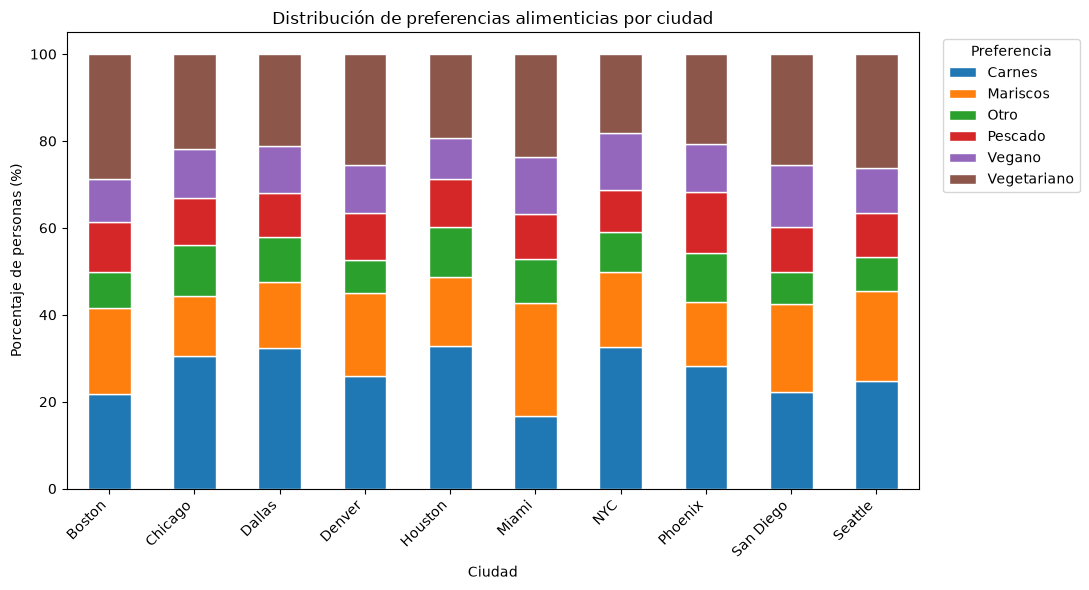

In [30]:
# Avance 3 - Mostrar cómo se distribuyen las preferencias alimenticias en todas las ciudades.
# Porcentaje de cada preferencia dentro de cada ciudad (cada fila suma 100%)
porc = (pd.crosstab(df['ciudad_residencia'], df['preferencias_alimenticias'], normalize='index') * 100).round(2)

porc.plot(kind='bar', stacked=True, figsize=(11, 6), edgecolor='white')

plt.title('Distribución de preferencias alimenticias por ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Porcentaje de personas (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Preferencia', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

count    2854.00
mean      690.03
std       212.59
min       420.77
25%       519.72
50%       639.12
75%       815.89
max      1499.70
Name: gasto_mensual, dtype: float64


,top_%,todos_%,diferencia
preferencias_alimenticias,,,
Carnes,26.21,27.09,-0.88
Vegetariano,24.39,22.75,1.64
Mariscos,18.47,18.18,0.29
Vegano,12.09,11.65,0.44
Pescado,10.51,10.71,-0.20
Otro,8.34,9.61,-1.27


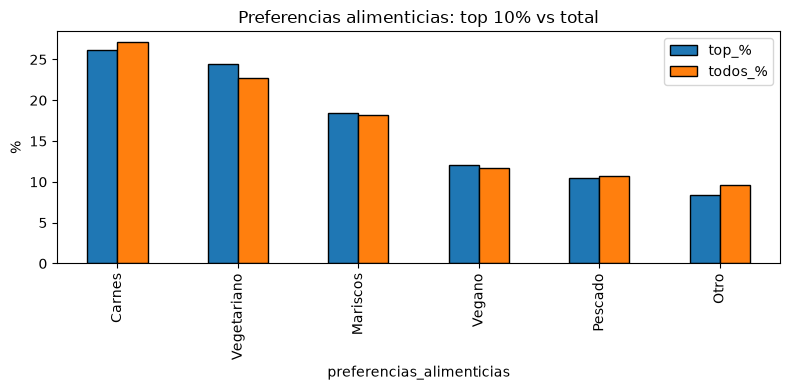

In [31]:
# Avance 3 - Perfilar los clientes de mayor gasto: Qué comidas les gustan, cuánto suelen gastar al mes.
# Top 10% de gasto mensual
d = df[(df['frecuencia_visita'] >= 0) & (df['promedio_gasto_comida'] > 0)].copy()
d['gasto_mensual'] = d['promedio_gasto_comida'] * d['frecuencia_visita']
top = d[d['gasto_mensual'] >= d['gasto_mensual'].quantile(0.90)]

# Cuánto gastan al mes
print(top['gasto_mensual'].describe().round(2))

# Qué comen (top vs total)
pref = pd.DataFrame({'top_%': top['preferencias_alimenticias'].value_counts(normalize=True) * 100,
                     'todos_%': d['preferencias_alimenticias'].value_counts(normalize=True) * 100}).round(2)
pref['diferencia'] = pref['top_%'] - pref['todos_%']
display(pref.sort_values('top_%', ascending=False))

pref[['top_%', 'todos_%']].plot(kind='bar', figsize=(8, 4), edgecolor='black')
plt.title('Preferencias alimenticias: top 10% vs total')
plt.ylabel('%')
plt.tight_layout()
plt.show()

In [32]:
#Avance 3 - ¿Cuál ciudad es en la que más membresías pagan?
#Queda una tabla con tres columnas por ciudad: personas, cantidad con membresía y porcentaje. La primera fila es la ciudad que más membresías tiene, y el print lo confirma.
tabla = (df.assign(con_membresia=df['membresia_premium'] == 'Sí')
           .groupby('ciudad_residencia')['con_membresia']
           .agg(personas='size', con_membresia='sum', porcentaje=lambda s: (s.mean() * 100).round(2))
           .sort_values('con_membresia', ascending=False))

display(tabla)
print('Ciudad con más membresías:', tabla['con_membresia'].idxmax())

,personas,con_membresia,porcentaje
ciudad_residencia,,,
Chicago,5384,2215,41.14
NYC,4769,1775,37.22
Miami,3186,1694,53.17
San Diego,3075,1502,48.85
Boston,2547,1139,44.72
Denver,2523,1068,42.33
Seattle,2191,1023,46.69
Dallas,2602,992,38.12
Houston,2212,808,36.53


Ciudad con más membresías: Chicago


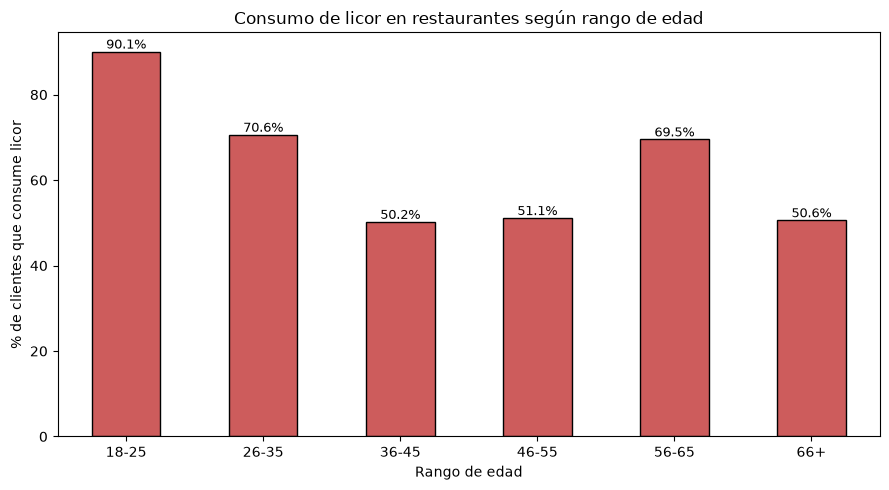

In [33]:
# Avance 3 - Generar un gráfico que muestre la relación entre el consumo de alcohol en los restaurantes y la edad de los clientes.
#Cada barra muestra qué porcentaje de las personas de ese rango consume licor, así que se pueden comparar rangos aunque tengan distinta cantidad de gente.
d = df[df['edad'].between(0, 110)].copy()

d['rango_edad'] = pd.cut(d['edad'],
                         bins=[0, 17, 25, 35, 45, 55, 65, 110],
                         labels=['0-17', '18-25', '26-35', '36-45', '46-55', '56-65', '66+'],
                         include_lowest=True)

pct = (d.groupby('rango_edad', observed=True)['consume_licor']
         .apply(lambda s: (s == 'Sí').mean() * 100)
         .round(2))

ax = pct.plot(kind='bar', figsize=(9, 5), color='indianred', edgecolor='black')
plt.title('Consumo de licor en restaurantes según rango de edad')
plt.xlabel('Rango de edad')
plt.ylabel('% de clientes que consume licor')
plt.xticks(rotation=0)
for b in ax.patches:
    ax.annotate(f'{b.get_height():.1f}%', (b.get_x() + b.get_width() / 2, b.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()